# 04 · 微服务网关、身份传递与配置管理（微服务02）


## 本章来源与学习路线

本篇依据百度网盘 `我的资源/day04-微服务02/PPT/微服务02.pptx`。原文件共 **67 页**，第 **20、26、62 页为隐藏页**，因此网盘预览显示 64 页。下文页码均按原 PPT 顺序，隐藏页中有用的流程说明也纳入笔记。整理日期：2026-10-09。

课件预览：[微服务02](https://pan.baidu.com/pfile/docview?path=%2F%E6%88%91%E7%9A%84%E8%B5%84%E6%BA%90%2Fday04-%E5%BE%AE%E6%9C%8D%E5%8A%A102%2FPPT%2F%E5%BE%AE%E6%9C%8D%E5%8A%A102.pptx&fsid=31437375193418&size=5386483&view_from=personal_file&md5=53062b7e6t31054d88d4fe7bbf781061&share=0&client=web&scene=main)。

| 阶段 | 原 PPT 页码 | 核心问题 |
| --- | --- | --- |
| 网关路由 | 1—17 | 前端如何通过统一入口访问不同服务 |
| 身份校验与传递 | 18—45 | 网关如何校验 JWT，服务之间如何延续用户身份 |
| 配置共享与热更新 | 46—62 | 怎样减少重复配置，并让业务参数变更后生效 |
| 动态路由 | 63—67 | 怎样把 Nacos 配置变化应用到网关路由表 |

**版本约定**：延续上一篇的 Java 11、Spring Boot 2.x、Spring Cloud 2021.0.x 时代示例，网关使用基于 WebFlux 的 Spring Cloud Gateway。课件采用 bootstrap 方式加载 Nacos 配置。精确依赖版本需从兼容矩阵选择，不将新版配置前缀或 Gateway MVC 实现混入旧版代码。

**示例说明**：“课件方案”来自 PPT；“整理示例”补全讲解所需代码；“补充/改进”解释边界。已读取原 PPT 文字并核对关键截图，未读取完整课程工程或实际启动网关、Nacos。代码中的 Lombok、常规 import 按需省略；项目专用的 JWT 工具不能仅凭课件任务描述还原。


## 1. 网关作为微服务的统一入口

上一篇解决了服务之间的调用，但浏览器仍需要知道商品、用户、订单等服务的地址。实例扩容或迁移后，让前端维护所有地址会增加耦合。（课件第 2—5 页）

**网关**位于客户端与业务服务之间，接收请求，判断目标服务，并承担入口处的身份校验等公共处理。

```text
浏览器 / App
     │ HTTP 请求、JWT
     ▼
API 网关
     ├── /items/** ──► 商品服务
     ├── /users/** ──► 用户服务
     ├── /carts/** ──► 购物车服务
     └── /orders/** ─► 交易服务
          │
          └── 通过 Nacos 发现实例，再选择实际地址
```

| 能力 | 解决的问题 |
| --- | --- |
| 路由 | 根据路径、方法等条件找到目标 |
| 转发与负载均衡 | 把请求发送给某个目标实例 |
| 身份校验 | 在入口识别未登录、无效或过期令牌 |
| 请求与响应过滤 | 处理内部请求头、日志等公共逻辑 |

网关可统一入口处的身份认证，业务服务仍需判断资源归属和业务权限。例如用户已登录，也不能查看其他人的订单。

网关自身也需要高可用与容量规划；所有流量经过一个单实例，不会自动获得容灾能力。


## 2. Spring Cloud Gateway 的运行模型

课件选择 Spring Cloud Gateway，并与当时常见的 Zuul 方案比较。（课件第 6 页）

| 课件中的实现 | 技术模型 | 阅读重点 |
| --- | --- | --- |
| Spring Cloud Gateway | 基于 WebFlux、Reactor，常用 Reactor Netty | 使用响应式过滤器链 |
| Netflix Zuul 1.x | 基于 Servlet 的阻塞式模型 | 课件对比针对这一代实现 |

WebFlux 用非阻塞处理组织请求，`Mono<Void>` 表示一段异步完成的处理过程。它不是普通方法中的“已经执行完毕”标记。

> 响应式框架不会把阻塞操作自动变成非阻塞。不要在网关事件循环中调用阻塞式数据库查询、`Thread.sleep` 或 `block()`。

课件“无需调优即可获得优异性能”的表述不能作为容量承诺。延迟还取决于过滤器逻辑、连接池、下游耗时和实际负载。

本篇的 Gateway 使用独立模块，避免引入 `spring-boot-starter-web` 或通过公共依赖带入 Servlet MVC。新版本存在其他 Gateway 技术栈，不能因此把本篇的 `ServerWebExchange`、`GlobalFilter` 代码直接搬到 MVC 网关。


## 3. 网关入门：依赖、启动与路由

**课件步骤**：创建网关模块 → 引入依赖 → 编写启动类 → 配置路由规则。（课件第 10—13 页）

**整理示例：hm-gateway 的主要依赖**。版本沿用兼容的父工程 BOM。

```xml
<dependency>
    <groupId>org.springframework.cloud</groupId>
    <artifactId>spring-cloud-starter-gateway</artifactId>
</dependency>
<dependency>
    <groupId>com.alibaba.cloud</groupId>
    <artifactId>spring-cloud-starter-alibaba-nacos-discovery</artifactId>
</dependency>
<dependency>
    <groupId>org.springframework.cloud</groupId>
    <artifactId>spring-cloud-starter-loadbalancer</artifactId>
</dependency>
```

```java
@SpringBootApplication
public class GatewayApplication {
    public static void main(String[] args) {
        SpringApplication.run(GatewayApplication.class, args);
    }
}
```

**application.yml 整理示例**：

```yaml
server:
  port: 8080
spring:
  application:
    name: hm-gateway
  cloud:
    nacos:
      server-addr: "${NACOS_SERVER_ADDR:127.0.0.1:8848}"
    gateway:
      routes:
        - id: item
          uri: lb://item-service
          predicates:
            - Path=/items/**,/search/**
        - id: user
          uri: lb://user-service
          predicates:
            - Path=/users/**
```

`lb://item-service` 表示按服务名发现实例并负载均衡；`http://127.0.0.1:8081` 则指向固定地址。`lb:/item-service` 少了一个斜杠，应使用 `lb://`。

**请求示例**：

```text
GET http://127.0.0.1:8080/items/list
  → 匹配 item 路由
  → 获取 item-service 的实例
  → 选择 8081 或 8083 等实际端口
  → GET http://127.0.0.1:8083/items/list
```

默认转发会保留路径。只有显式配置 StripPrefix、RewritePath 等过滤器，才会按规则修改路径。

| 本机联调端口整理示例 | 应用 |
| --- | --- |
| 8080 | 网关 |
| 8081、8083 | 商品服务两个实例 |
| 8082 | 用户服务 |
| 8084 | 购物车服务 |
| 8085 | 交易服务 |

上一篇购物车示例占用 8080，引入网关后需调整端口。表中只是避免本机端口冲突的示例，实际端口由工程配置决定。


## 4. 路由属性与匹配规则

网关需要先判断请求是否适用某条规则，再决定转发到哪里、如何处理。（课件第 15 页）

路由配置对应 `RouteDefinition`，主要属性如下：

| 属性 | 含义 | 示例 |
| --- | --- | --- |
| id | 唯一路由标识 | `item` |
| uri | 目标地址或逻辑服务名 | `lb://item-service` |
| predicates | 匹配请求的断言 | `Path=/items/**` |
| filters | 匹配后执行的过滤器 | `StripPrefix=1` |

**断言**回答“是否适用这条路由”，**过滤器**处理匹配后的请求与响应。

```yaml
spring:
  cloud:
    gateway:
      routes:
        - id: item-read
          uri: lb://item-service
          predicates:
            - Path=/items/**,/search/**
            - Method=GET
```

此例要求路径与方法**同时**匹配；同一个 Path 断言内列出的多个路径模式满足其中一个即可。

多个路由同时匹配时，要检查路由顺序和具体匹配范围。补充属性 `order` 可用于排序，数值较小的通常先参与匹配；不能期待网关自动选择“路径看起来最具体”的路由。


## 5. 路由断言工厂

断言工厂把配置转换成请求判断逻辑。课件列出 12 类，数量反映当时的版本，不是所有版本的固定总数。（课件第 16 页）

| 名称 | 判断内容 | 配置示例 |
| --- | --- | --- |
| After | 时间晚于指定时刻 | `After=2037-01-20T17:42:47-07:00[America/Denver]` |
| Before | 时间早于指定时刻 | `Before=2031-04-13T15:14:47+08:00[Asia/Shanghai]` |
| Between | 时间在两个时刻之间 | `Between=2031-04-13T00:00:00+08:00[Asia/Shanghai],2031-04-14T00:00:00+08:00[Asia/Shanghai]` |
| Cookie | Cookie 名称与值匹配 | `Cookie=chocolate,ch.p` |
| Header | 请求头存在且值匹配 | `Header=X-Request-Id,\d+` |
| Host | 请求域名匹配 | `Host=**.somehost.org` |
| Method | HTTP 方法匹配 | `Method=GET,POST` |
| Path | 请求路径匹配 | `Path=/items/**` |
| Query | 查询参数存在或值匹配 | `Query=name,^Jack$` |
| RemoteAddr | 直接连接方地址处于指定网段 | `RemoteAddr=192.168.1.0/24` |
| Weight | 在相同分组的路由间按权重分配 | `Weight=group1,2` |
| XForwardedRemoteAddr | 基于转发来源地址判断 | `XForwardedRemoteAddr=192.168.1.0/24` |

课件将 Between 的解释写成“之前”，应理解为**区间之间**。时间断言要注意时区，正则匹配要区分存在性与值的限制。

Weight 的 2、8 表示同一组内的相对权重，长期分配大致为 20% / 80%；它与一个服务内部多个实例的负载均衡是不同层次。

来源 IP 判断涉及可信代理边界。部署在反向代理后时，RemoteAddr 可能是代理 IP；直接相信客户端自填的 X-Forwarded-For，也不能得到可信真实来源。


## 6. 内置路由过滤器与默认过滤器

请求路径、内部请求头和响应头有时需要在网关统一处理。课件介绍路由过滤器，并列举其中几种。（课件第 17、25 页）

| 过滤器 | 作用 | 示例 |
| --- | --- | --- |
| AddRequestHeader | 添加请求头 | `AddRequestHeader=X-Source,gateway` |
| RemoveRequestHeader | 移除请求头 | `RemoveRequestHeader=X-Debug` |
| AddResponseHeader | 添加响应头 | `AddResponseHeader=X-From,hm-gateway` |
| RemoveResponseHeader | 移除响应头 | `RemoveResponseHeader=X-Internal` |
| RewritePath | 按正则重写路径 | 见下例 |
| StripPrefix | 去掉前 N 段路径 | `StripPrefix=1` |

过滤器名称区分大小写，课件中的 `AddrequestHeader` 应写成 `AddRequestHeader`。

**按单条路由使用**：

```yaml
spring:
  cloud:
    gateway:
      routes:
        - id: item-api
          uri: lb://item-service
          predicates:
            - Path=/api/items/**
          filters:
            - StripPrefix=1
```

请求 `/api/items/1` 转发为 `/items/1`。如果提供者的真实接口仍是 `/api/items/1`，就不该剥离这个前缀。

**默认作用于所有路由**：

```yaml
spring:
  cloud:
    gateway:
      default-filters:
        - AddRequestHeader=X-Source,gateway
```

**RewritePath 整理示例**，与 StripPrefix 方案按需选择：

```yaml
spring:
  cloud:
    gateway:
      routes:
        - id: red
          uri: lb://item-service
          predicates:
            - Path=/red/**
          filters:
            - RewritePath=/red/?(?<segment>.*), /$\{segment}
```

`/red/items/1` 会改为 `/items/1`。此处 `$\{segment}` 是课件时代 YAML 示例的转义写法，用来保留正则替换组，避免与 Spring 的属性占位符混淆。

default-filters 仍属于配置到路由上的 GatewayFilter，不等于 GlobalFilter。


## 7. 网关过滤器链与执行顺序

登录校验必须发生在转发之前，因此需要理解网关如何处理请求。（课件第 20 隐藏页、23—26 页）

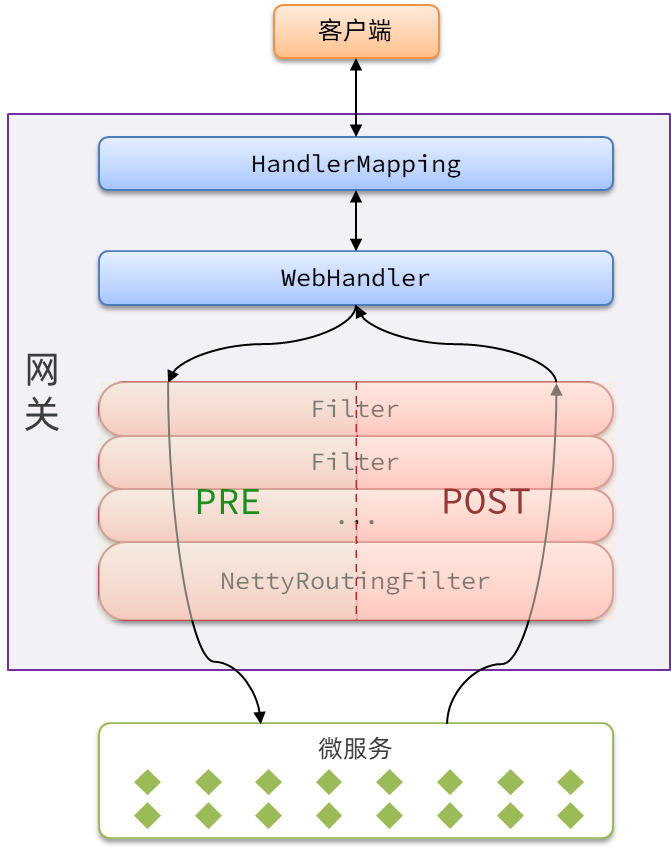

| 阶段 | 主要动作 |
| --- | --- |
| 路由匹配 | RoutePredicateHandlerMapping 找到符合条件的路由 |
| 构建过滤器链 | FilteringWebHandler 合并路由过滤器与全局过滤器并排序 |
| PRE | 校验身份、修改下游请求等 |
| 转发 | 由相关路由过滤器完成实际网络请求 |
| POST | 在响应返回时做后续处理 |

```text
Filter A 的 PRE
  → Filter B 的 PRE
    → 转发到服务
  ← Filter B 的 POST
← Filter A 的 POST
```

过滤器实现 `Ordered` 或获得对应 order 后，数值越小，优先级越高。普通的嵌套链条中，PRE 正序、POST 逆序；实际 POST 是否运行还取决于响应式操作符、错误和取消。

> `chain.filter(exchange)` 表示把处理交给后续链。修改了 exchange，却继续传旧对象，修改不会进入下游请求。

GlobalFilter 作用于匹配到网关路由的请求，并不意味着它替代了应用中所有 Web 请求处理。未匹配路由、其他 Web 端点等需要按实际安全边界处理。


## 8. 自定义 GlobalFilter

当所有路由都需要某种公共逻辑时，可以把它实现为 GlobalFilter，注册为 Spring Bean 后参与过滤器链。（课件第 25—26、29 页）

**整理示例**：

```java
@Component
public class TraceGlobalFilter implements GlobalFilter, Ordered {
    private static final Logger log =
        LoggerFactory.getLogger(TraceGlobalFilter.class);

    @Override
    public Mono<Void> filter(ServerWebExchange exchange,
                             GatewayFilterChain chain) {
        String path = exchange.getRequest().getPath().value();
        log.debug("PRE path={}", path);
        return chain.filter(exchange)
            .then(Mono.fromRunnable(() ->
                log.debug("POST completed path={}", path)));
    }

    @Override
    public int getOrder() {
        return -100;
    }
}
```

此处日志类型使用 `org.slf4j.Logger`，与上一篇配置 Feign 记录等级时的 `feign.Logger` 不同。

`then(...)` 中的后续逻辑在上游成功完成后执行；发生异常或取消时不一定执行。若要做终止统计，可考虑 `doFinally` 等操作符，并区分成功、异常和取消。

身份校验失败时，不调用 chain，设置响应状态并返回 `response.setComplete()`，即可结束当前请求；不能返回 `null`。


## 9. 自定义 GatewayFilterFactory

路由过滤器适合“只对指定路由生效”或“由 YAML 传参数”的场景。（课件第 27—28 页）

| 类型 | 注册和使用方式 | 典型场景 |
| --- | --- | --- |
| GlobalFilter | 作为 Bean 自动参与匹配路由的链 | 通用入口身份校验 |
| GatewayFilter | 通常由工厂创建，再配置到路由 | 某路由特有的参数化处理 |

若要通过 YAML 使用自定义过滤器，应编写继承 `AbstractGatewayFilterFactory` 的工厂，而不是仅把一个 GatewayFilter 实现类注册为普通 Bean。

**按课件 PrintAny 思路重建的示例**：

```java
@Component
public class PrintAnyGatewayFilterFactory
        extends AbstractGatewayFilterFactory<
            PrintAnyGatewayFilterFactory.Config> {
    private static final Logger log =
        LoggerFactory.getLogger(PrintAnyGatewayFilterFactory.class);

    public PrintAnyGatewayFilterFactory() {
        super(Config.class);
    }

    @Override
    public List<String> shortcutFieldOrder() {
        return List.of("a", "b", "c");
    }

    @Override
    public GatewayFilter apply(Config config) {
        return (exchange, chain) -> {
            log.debug("PrintAny: {}, {}, {}",
                config.getA(), config.getB(), config.getC());
            return chain.filter(exchange);
        };
    }

    @Data
    public static class Config {
        private String a;
        private String b;
        private String c;
    }
}
```

```yaml
spring:
  cloud:
    gateway:
      default-filters:
        - PrintAny=1,2,3
```

工厂名去掉 `GatewayFilterFactory` 后缀后得到配置名 `PrintAny`；快捷参数按 `shortcutFieldOrder` 的顺序绑定到 a、b、c。`super(Config.class)` 把配置类型交给父类处理。

此示例只展示配置绑定。实际业务应选择有意义的参数并校验；若需要精确执行顺序，应返回带顺序的过滤器，例如 `OrderedGatewayFilter`，不能认为工厂本身的声明顺序就等于执行顺序。


## 10. JWT 登录校验的业务链路

商品浏览可以公开，购物车、订单等操作则需要知道当前用户。课件把原 hm-service 中的 JWT 校验能力迁入网关，在转发前统一处理。（课件第 19、21、31 页）

**JWT** 是携带声明信息的令牌格式。签名校验用于确认令牌可信，过期校验用于判断它是否仍有效；仅 Base64 解码出用户 ID，不能证明用户已通过认证。

```text
登录：客户端 → 用户服务校验账号 → 返回 JWT

后续请求：客户端携带 JWT → 网关
   ├── 公开接口：按白名单策略放行
   └── 受保护接口：
         验证签名、有效期及业务要求的声明
             ├── 无效：返回 401
             └── 有效：得到用户身份 → 转发
```

| 情况 | 处理原则 |
| --- | --- |
| 未携带令牌，访问受保护接口 | 返回 401 Unauthorized |
| 签名错误、过期、声明无效 | 返回 401 |
| 身份有效，但无资源权限 | 通常返回 403 Forbidden，由对应授权逻辑处理 |
| 登录、公开商品查询 | 按明确的路径与方法白名单放行 |

白名单要表达具体业务。例如只公开 GET 商品查询，不应因为把 `/items/**` 整段放行，就连商品修改接口也公开。

**课件边界**：PPT 要求复用现有 JWT 工具，但没有给出工具完整实现、密钥配置或令牌字段定义。下面用 `JwtVerifier` 表示适配接口，真实工程应接入经过配置的 JWT 验证器，不能把它替换成“直接读 payload”。


## 11. 网关登录过滤器的整理示例

网关要完成公开接口判断、令牌验证、失败响应和身份头写入。还要先删除客户端自填的内部用户头，避免公开接口绕过校验后携带伪造身份。

**验证器适配契约**：

```java
public interface JwtVerifier {
    Long verifyUserId(String token) throws InvalidTokenException;
}
```

`InvalidTokenException` 为整理示例专用异常，需在工程中定义，例如：

```java
public class InvalidTokenException extends RuntimeException {
    public InvalidTokenException(String message, Throwable cause) {
        super(message, cause);
    }
}
```

适配实现应验证签名、有效期，以及工程要求的 issuer / audience 等声明，再提取用户 ID。只把预期的令牌无效情况转成此异常；密钥加载失败等系统错误不应统一伪装成“用户未登录”。

**GlobalFilter 整理示例**，采用 `Authorization: Bearer <JWT>` 约定：

```java
@Component
@RequiredArgsConstructor
public class AuthGlobalFilter implements GlobalFilter, Ordered {
    private static final String USER_HEADER = "user-info";
    private final JwtVerifier jwtVerifier;
    private final AntPathMatcher pathMatcher = new AntPathMatcher();

    @Override
    public Mono<Void> filter(ServerWebExchange exchange,
                             GatewayFilterChain chain) {
        // 所有请求先清除外部传入的内部身份
        ServerHttpRequest cleanRequest = exchange.getRequest().mutate()
            .headers(headers -> headers.remove(USER_HEADER))
            .build();
        ServerWebExchange cleanExchange = exchange.mutate()
            .request(cleanRequest)
            .build();

        if (isPublic(cleanRequest)) {
            return chain.filter(cleanExchange);
        }

        List<String> values =
            cleanRequest.getHeaders().get(HttpHeaders.AUTHORIZATION);
        if (values == null || values.size() != 1) {
            return unauthorized(cleanExchange);
        }
        String authorization = values.get(0);
        if (!authorization.regionMatches(true, 0, "Bearer ", 0, 7)) {
            return unauthorized(cleanExchange);
        }
        String token = authorization.substring(7).trim();
        if (token.isEmpty()) {
            return unauthorized(cleanExchange);
        }

        final Long userId;
        try {
            userId = jwtVerifier.verifyUserId(token);
        } catch (InvalidTokenException e) {
            return unauthorized(cleanExchange);
        }
        if (userId == null) {
            return unauthorized(cleanExchange);
        }

        ServerHttpRequest downstream = cleanRequest.mutate()
            .headers(headers -> headers.set(USER_HEADER, userId.toString()))
            .build();
        return chain.filter(cleanExchange.mutate()
            .request(downstream)
            .build());
    }

    private boolean isPublic(ServerHttpRequest request) {
        String path = request.getPath().value();
        HttpMethod method = request.getMethod();
        return (HttpMethod.POST.equals(method) && "/users/login".equals(path))
            || (HttpMethod.GET.equals(method)
                && (pathMatcher.match("/items/**", path)
                    || pathMatcher.match("/search/**", path)));
    }

    private Mono<Void> unauthorized(ServerWebExchange exchange) {
        exchange.getResponse().setStatusCode(HttpStatus.UNAUTHORIZED);
        return exchange.getResponse().setComplete();
    }

    @Override
    public int getOrder() {
        return -100;
    }
}
```

白名单为整理示例，应与真实路由及前端令牌约定一致。JWT 验证器需要作为 Bean 注册；如果课程前端使用不同的令牌格式，应按真实契约适配，而不是只改前端或只改网关一侧。

跨域请求还需要相应 CORS 配置与预检处理。不要通过“所有 OPTIONS 一律当登录成功”代替完整跨域策略。

网关基于 WebFlux，不能把解析出的用户 ID 放进普通 ThreadLocal 后期待后续响应式阶段一直可见。这里把身份写到新建的下游请求中。


## 12. 网关向业务服务传递用户

身份校验发生在网关，但购物车和订单服务需要用户 ID。课件采用**内部请求头传递身份**。（课件第 33—37 页）

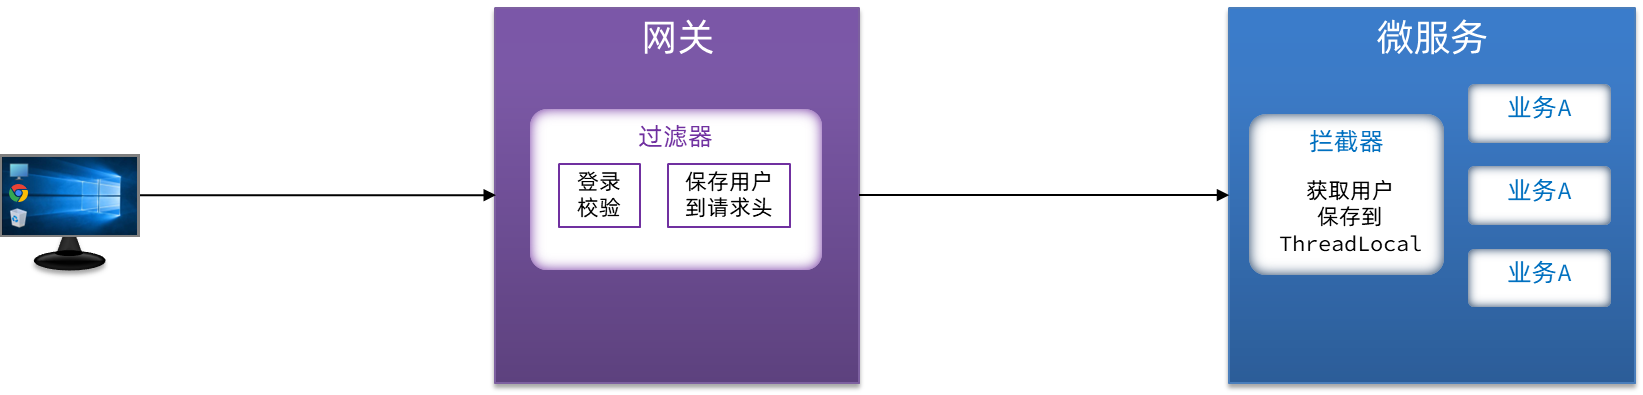

课件 API 的关键用法：

```java
ServerWebExchange downstreamExchange = exchange.mutate()
    .request(builder -> builder.headers(headers ->
        headers.set("user-info", userId.toString())))
    .build();

return chain.filter(downstreamExchange);
```

`ServerHttpRequest` 与 `ServerWebExchange` 采用不可变对象的修改方式。`mutate().build()` 构造新对象，并没有把原 exchange 原地改掉。

| 写法 | 结果 |
| --- | --- |
| 新建 exchange 后传给 chain | 下游可以收到修改后的请求 |
| 新建 exchange 却继续传原对象 | 下游仍收到旧请求 |
| 反复添加同名身份头 | 可能出现多个值，解释不一致 |
| 使用 `headers.set` 并清理外部输入 | 保持一个由网关确定的身份值 |

**可信边界**：普通请求头可以伪造。服务只信任 `user-info` 的前提，是入口清理外部同名头，并限制业务服务被任意外部客户端绕过网关直接访问；更严格的部署可使用内部认证或签名身份凭据。

场景一：外部请求带 `user-info: 999`，但令牌属于用户 12，最终只能写入用户 12。场景二：公开商品查询不带令牌，外部伪造的身份头也应清除，不能把“公开接口放行”变成身份伪造入口。


## 13. Servlet 微服务的用户上下文

业务方法层层传 `userId` 容易重复。课件在微服务入口读取内部请求头，再保存到当前请求线程的 ThreadLocal，供业务代码使用。（课件第 35—37、43 页）

**ThreadLocal** 为每个线程保存独立值。Servlet 同步请求通常在同一个线程中调用 Controller、Service，因此可在该链路内读取。

**整理示例：UserContext**：

```java
public final class UserContext {
    private static final ThreadLocal<Long> USER = new ThreadLocal<>();

    private UserContext() {
    }

    public static void setUser(Long userId) {
        USER.set(userId);
    }

    public static Long getUser() {
        return USER.get();
    }

    public static void removeUser() {
        USER.remove();
    }
}
```

**同步 Spring MVC 拦截器整理示例**：

```java
public class UserInfoInterceptor implements HandlerInterceptor {
    @Override
    public boolean preHandle(HttpServletRequest request,
                             HttpServletResponse response,
                             Object handler) {
        UserContext.removeUser();
        List<String> values =
            Collections.list(request.getHeaders("user-info"));
        if (values.isEmpty()) {
            return true; // 公开请求可以没有身份
        }
        if (values.size() != 1) {
            response.setStatus(HttpServletResponse.SC_BAD_REQUEST);
            return false;
        }
        try {
            long userId = Long.parseLong(values.get(0));
            if (userId <= 0) {
                response.setStatus(HttpServletResponse.SC_BAD_REQUEST);
                return false;
            }
            UserContext.setUser(userId);
            return true;
        } catch (NumberFormatException e) {
            response.setStatus(HttpServletResponse.SC_BAD_REQUEST);
            return false;
        }
    }

    @Override
    public void afterCompletion(HttpServletRequest request,
                                HttpServletResponse response,
                                Object handler, Exception ex) {
        UserContext.removeUser();
    }
}
```

本文 Boot 2.x 示例使用 `javax.servlet.http` 类型；Boot 3 迁移为 `jakarta.servlet`，不能只替换一个 import 就认为整个项目兼容。

> 线程池会复用线程。请求结束必须 `remove()`，否则后一个请求可能读到前一个用户，或长期保留无用引用。

无身份时放行仅表示允许进入后续业务，不等于所有业务都允许匿名。受保护接口仍需在服务边界明确检查身份和权限。

此示例面向同步 Servlet 请求。Servlet 异步处理还需在 `afterConcurrentHandlingStarted` 等生命周期清理原线程，并处理异步线程中的身份；普通 ThreadLocal 不会自动解决这些问题。


## 14. 公共拦截器的注册与技术栈隔离

课件建议把用户拦截器放在 hm-common，避免每个服务重复实现。但**引用公共 Jar 不代表其中任意配置自动生效**。（课件第 37 页）

**整理示例：只在 Servlet Web 应用中注册**：

```java
@Configuration(proxyBeanMethods = false)
@ConditionalOnWebApplication(type = ConditionalOnWebApplication.Type.SERVLET)
public class UserMvcConfig implements WebMvcConfigurer {
    @Override
    public void addInterceptors(InterceptorRegistry registry) {
        registry.addInterceptor(new UserInfoInterceptor())
            .addPathPatterns("/**");
    }
}
```

业务服务可通过 `@Import(UserMvcConfig.class)` 显式引入；也可以把它做成按 Spring Boot 对应版本注册的自动配置。

| 注册方式 | 使用要点 |
| --- | --- |
| 显式 Import | 易看清哪些服务启用，适合入门 |
| 普通组件扫描 | 配置类必须位于实际扫描范围 |
| Boot 自动配置 | 必须提供对应版本要求的自动配置注册文件与条件 |

Boot 2.x 常见 `META-INF/spring.factories` 的 EnableAutoConfiguration 注册；Boot 2.7 也支持 `AutoConfiguration.imports` 等机制。应按工程版本选择，不能把一个普通 `@Configuration` 类放入依赖就假设它会被发现。

hm-common 的 MVC 相关依赖也需妥善管理。不能为了让拦截器编译，在响应式网关里传递引入整个 `spring-boot-starter-web`。可通过模块拆分、可选依赖和 Web 类型条件控制。

网关负责响应式入口过滤；Servlet 微服务使用 MVC 拦截器。两者分属不同请求模型。


## 15. OpenFeign 向下游传递用户

交易服务调用购物车清理接口时，请求由 Feign 新建。原浏览器请求头不会自动进入这个新请求，下游也无法直接读取上游线程里的 UserContext。（课件第 39—45 页）

```text
客户端 JWT
    ↓
网关：校验 → 写 user-info
    ↓
交易服务 MVC 拦截器：读取 → 本线程 UserContext
    ↓
Feign RequestInterceptor：读取上下文 → 写出站请求头
    ↓
购物车服务 MVC 拦截器：读取 → 自己的 UserContext
    ↓
按当前用户清理购物车
```

Feign 提供 `feign.RequestInterceptor` 与 `feign.RequestTemplate`，可以在发出请求前修改请求头。

**整理示例**：

```java
public class UserFeignConfig {
    @Bean
    public RequestInterceptor userInfoRequestInterceptor() {
        return template -> {
            template.removeHeader("user-info");
            Long userId = UserContext.getUser();
            if (userId != null) {
                template.header("user-info", userId.toString());
            }
        };
    }
}
```

在需要传递身份的内部 Client 上引入：

```java
@FeignClient(
    name = "cart-service",
    configuration = UserFeignConfig.class
)
public interface CartClient {
    @DeleteMapping("/carts")
    void deleteByItemIds(@RequestParam("ids") Collection<Long> ids);
}
```

CartClient 的路径与方法是整理示例，必须与真实购物车接口一致。RequestInterceptor 配置应与 Client 扫描一起确认；只定义类和方法不代表它已注册。

也可通过 `@EnableFeignClients(defaultConfiguration = UserFeignConfig.class)` 作为公共默认配置，但应限定在可信内部服务调用中，避免把内部身份头发送给第三方接口。

无用户上下文时不应伪造默认用户，也不要把它写成 `"null"`。后台任务调用受保护接口，需要单独设计服务身份与调用权限。


## 16. 线程上下文与业务授权的边界

ThreadLocal 只覆盖当前线程内的同步访问。把代码改成异步，或放进响应式网关，不会自动延续用户身份。

| 执行场景 | 身份处理 |
| --- | --- |
| Servlet 同线程同步调用 Feign | 当前请求的 ThreadLocal 可被拦截器读取 |
| 线程池、CompletableFuture、异步任务 | 明确传入必要身份；若设置 ThreadLocal，必须在 finally 清理 |
| Reactor 响应式流程 | 使用适合响应式链路的 Context 或请求对象 |
| 消息队列与定时任务 | 明确业务操作者、服务身份和可信来源 |

不要用全局静态变量保存“当前用户”，也不要把 InheritableThreadLocal 当成线程池传播与清理的通用答案。

**授权例子**：查询购物车时，应从可信 UserContext 获得 userId，并将它用于数据过滤。删除订单时，除了核实用户已登录，还要检查订单是否属于该用户、状态是否允许删除。

身份传递让下游知道“谁在请求”，业务授权回答“他能否操作这条数据”。它们需要在调用链中共同成立。


## 17. Nacos 配置管理解决的问题

服务数量增加后，日志、数据库模板和客户端配置会重复；购物车上限等业务参数又经常变化。每次修改都重新打包、重启，会增加维护成本。（课件第 47—48 页）

**配置中心**集中保存配置，应用启动时读取，并可监听后续变化。

| Nacos 能力 | 保存的内容 | 解决的问题 |
| --- | --- | --- |
| 服务注册发现 | 服务名、实例地址与状态 | 去哪里调用服务 |
| 配置管理 | 应用参数与配置文档 | 应用按哪些参数运行 |

二者可由同一 Nacos Server 提供，但客户端依赖与配置入口不同。引入 discovery starter，不会自动代替 config starter。

```text
共享配置 → 多个服务读取
应用专用配置 → 对应服务读取
路由配置 → 网关监听并转换为路由定义

Nacos 发布变更
    → 客户端收到变化
    → 更新配置源
    → 对应绑定、刷新或路由更新机制生效
```

配置中心能够通知变化，不代表任意对象都会自动重建。连接池、第三方客户端和业务对象是否热更新，需要分别验证。


## 18. 配置的定位：namespace、group 与 Data ID

同名配置可能属于不同环境，应用必须知道“读哪一份”。（课件第 50—51 页）

| 维度 | 作用 | 示例 |
| --- | --- | --- |
| namespace | 隔离环境或租户 | dev / test / prod 对应的 namespace ID |
| group | 对配置分组 | DEFAULT_GROUP |
| Data ID | 标识某份配置文档 | shared-jdbc.yaml、cart-service-dev.yaml |

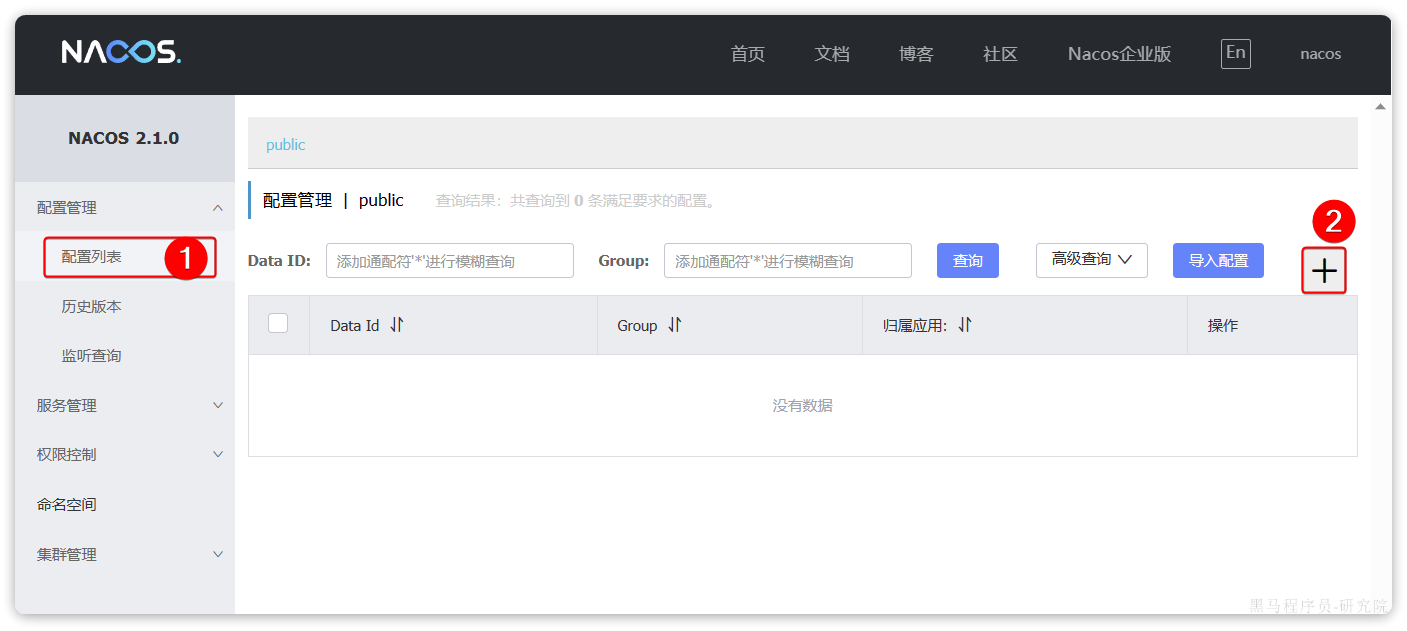

课件截图显示 Nacos 2.1.0 控制台、public namespace 与 DEFAULT_GROUP。它反映截图环境，不是要求所有工程必须使用相同服务端版本。

通常客户端的 namespace 属性填写**命名空间 ID**，不是控制台显示名称。Data ID 的扩展名也要一致：`shared-jdbc.yaml` 与 `shared-jdbc.yml` 是两个不同名字。

**应用专用配置命名示例**：

```text
spring.application.name = cart-service
spring.profiles.active = dev
file-extension = yaml

基础应用配置：cart-service.yaml
环境专用配置：cart-service-dev.yaml
```

课件第 60、62 页的属性名存在拼写问题，应使用 `spring.application.name` 和 `spring.profiles.active`。应用专用配置名称也可能受 prefix 等属性影响，应与真实客户端版本和配置一致。


## 19. 共享配置与服务差异参数

共享的重点是提取稳定公共项，同时保留每个服务自己的数据库名、接口文档信息等差异。（课件第 50—51 页）

| 课件列举的共享内容 | 适合共享的部分 | 仍需按服务区分 |
| --- | --- | --- |
| JDBC / MyBatisPlus | 驱动、通用连接模板、通用 ORM 策略 | 数据库名、账号、业务 Mapper |
| 日志 | 格式与公共日志级别 | 服务名、包路径与输出位置 |
| Swagger 等接口文档 | 通用开关或规范 | 项目名称、分组、扫描包 |
| OpenFeign | 公共超时、HTTP 客户端设置 | 某个 Client 的特殊契约与预算 |

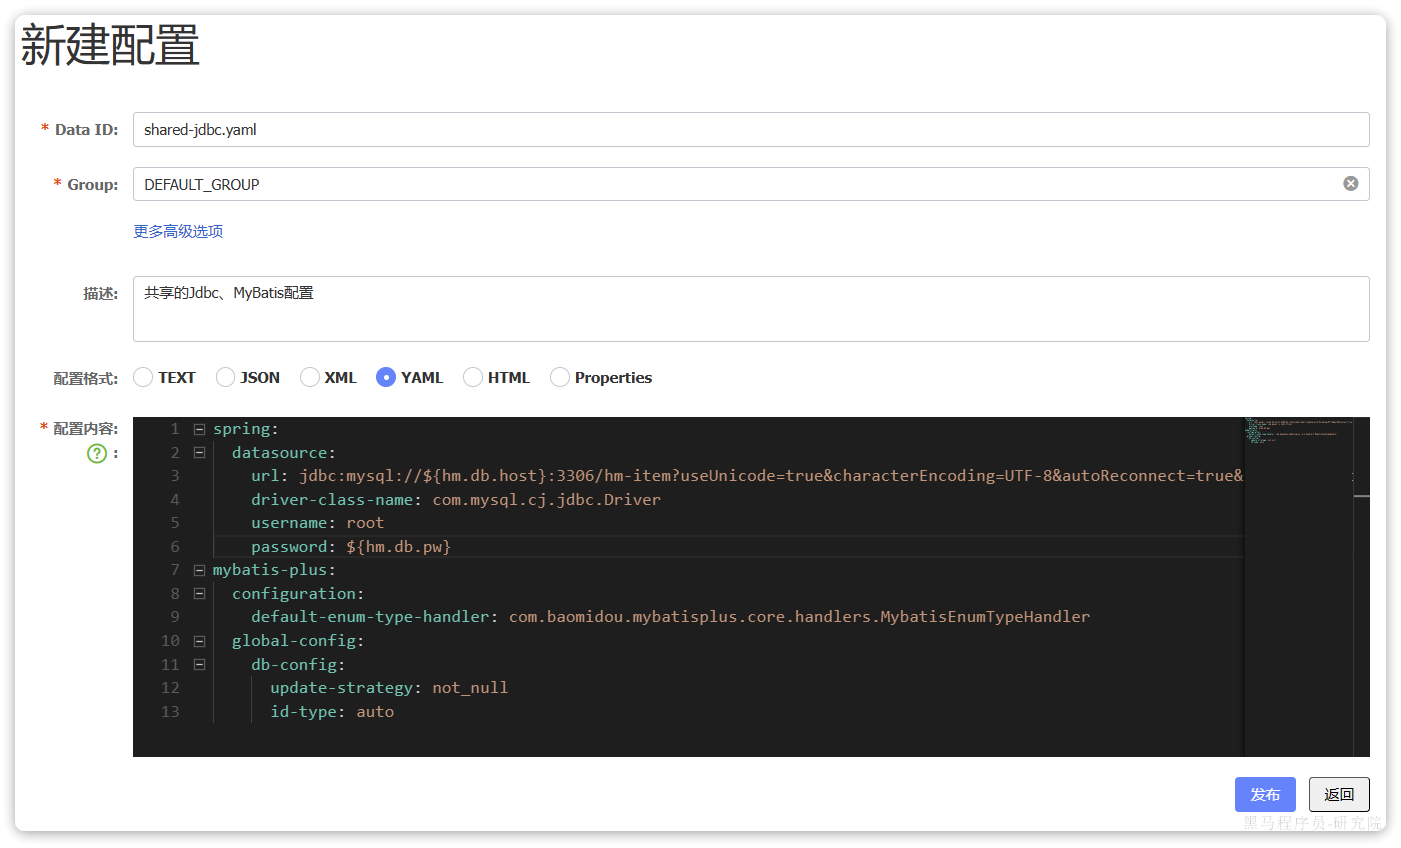

截图把数据库写成 `hm-item`、用户名写成 root。以下整理示例进一步参数化数据库与账号，不要求所有服务读写同一个库。

**Nacos 中 shared-jdbc.yaml 的整理示例**：

```yaml
spring:
  datasource:
    url: "jdbc:mysql://${hm.db.host}:3306/${hm.db.database}?useUnicode=true&characterEncoding=UTF-8"
    driver-class-name: com.mysql.cj.jdbc.Driver
    username: "${hm.db.username}"
    password: "${hm.db.pw}"
mybatis-plus:
  configuration:
    default-enum-type-handler: com.baomidou.mybatisplus.core.handlers.MybatisEnumTypeHandler
  global-config:
    db-config:
      update-strategy: not_null
      id-type: auto
```

**购物车服务自己的 application.yml 片段**：

```yaml
server:
  port: 8084
hm:
  db:
    host: "${DB_HOST:127.0.0.1}"
    database: hm-cart
    username: "${DB_USERNAME}"
    pw: "${DB_PASSWORD}"
```

需要在实际运行环境提供 DB_USERNAME 与 DB_PASSWORD。示例表达配置来源关系，不包含真实账号；驱动依赖、数据库初始化与权限仍由各服务配置。

共享模板通过占位符引用服务差异值，避免把“减少重复配置”变成“所有服务都使用商品库”。MyBatisPlus 策略仍应与业务一致，不能因共享就改变主键或更新语义。


## 20. bootstrap 加载 Nacos 共享配置

数据源等 Bean 在应用初始化时就要读取参数，因此远程配置必须在相关 Bean 创建前进入 Environment。（课件第 52—57 页）

**课件方案**：引入 Nacos config 与 bootstrap 支持，在早期引导阶段拉取配置。

```xml
<dependency>
    <groupId>com.alibaba.cloud</groupId>
    <artifactId>spring-cloud-starter-alibaba-nacos-config</artifactId>
</dependency>
<dependency>
    <groupId>org.springframework.cloud</groupId>
    <artifactId>spring-cloud-starter-bootstrap</artifactId>
</dependency>
```

**bootstrap.yaml 整理示例**：

```yaml
spring:
  application:
    name: cart-service
  profiles:
    active: dev
  cloud:
    nacos:
      server-addr: "${NACOS_SERVER_ADDR:127.0.0.1:8848}"
      config:
        namespace: "${NACOS_NAMESPACE:}"
        group: DEFAULT_GROUP
        file-extension: yaml
        shared-configs:
          - data-id: shared-jdbc.yaml
            group: DEFAULT_GROUP
            refresh: false
          - data-id: shared-log.yaml
            group: DEFAULT_GROUP
            refresh: true
          - data-id: shared-swagger.yaml
            group: DEFAULT_GROUP
            refresh: false
```

此例的 refresh 开关为整理补充：共享配置是否监听变化需显式考虑，不能只写共享文件名就认为全部可以热更新。即便 refresh 为 true，也只说明参与配置刷新，不能保证数据源等运行对象会重建。

```text
启动
  → 读取 bootstrap 中的服务名、环境和 Nacos 地址
  → 拉取共享配置与应用配置
  → 合并到应用 Environment
  → 初始化使用这些配置的业务 Bean
```

流程用于理解依赖关系，不是所有版本内部事件的逐行时序。新版可采用 `spring.config.import` 等 Config Data 方式；那是一套需要按版本迁移的配置入口，不应和课件 bootstrap 片段随意拼接。

| 排查点 | 典型问题 |
| --- | --- |
| bootstrap 支持 | 文件存在，但对应加载机制未启用 |
| Nacos 地址 | 缺少端口、容器 localhost 指向错误或网络不可达 |
| namespace / group / Data ID | 文件看起来存在，客户端实际读取的是另一位置 |
| YAML 格式 | 缩进或字段拼写错误 |
| 实际属性来源 | 多份文档定义同一个键，生效值来自别处 |

不要笼统记忆“本地永远覆盖远端”或相反。配置源优先级受加载模式、客户端版本与覆盖设置影响，遇到同名键时应检查应用实际的属性来源；优先通过模板引用差异参数，减少不必要的同名覆盖。


## 21. 热更新：配置源变化与 Bean 读取方式

Nacos 中的值变了，业务代码仍可能使用初始化时保存的旧值。课件给出两种读取方式来支持业务配置刷新。（课件第 59—60、62 隐藏页）

| 方式 | 机制与前提 |
| --- | --- |
| `@ConfigurationProperties` | 配置刷新机制触发属性重新绑定；类需作为 Bean 注册 |
| `@Value` + `@RefreshScope` | 刷新时使作用域中的旧实例失效，后续调用使用新实例 |

**方案一：配置属性对象**，以购物车上限为例：

```java
@Data
@ConfigurationProperties(prefix = "hm.cart")
public class CartProperties {
    private int maxItems = 10;
}
```

在配置类或启动类注册它：

```java
@EnableConfigurationProperties(CartProperties.class)
@Configuration(proxyBeanMethods = false)
public class CartConfig {
}
```

**Nacos 中 cart-service-dev.yaml**：

```yaml
hm:
  cart:
    max-items: 10
```

**方案二：Value 与 RefreshScope**，与上面的属性对象方案按需选择：

```java
@Component
@RefreshScope
public class CartLimitValue {
    @Value("${hm.cart.max-items:10}")
    private int maxItems;

    public int getMaxItems() {
        return maxItems;
    }
}
```

`max-items` 是推荐的配置命名形式，ConfigurationProperties 可绑定到 Java 的 `maxItems` 字段。普通 Bean 上的 `@Value` 通常只在创建时注入，不能仅因 Nacos 文档变动就假设字段会更新。

> 这两种方案都依赖配置客户端和 Spring Cloud 刷新机制正常工作。注解本身不会替应用连接 Nacos，也不会自动修复错误的 Data ID。

变化范围也要判断：购物车上限这类运行时读取的业务参数容易刷新；数据库连接地址、服务监听端口等参数是否支持动态生效，需要对应组件机制，不能类推。


## 22. 购物车商品数量上限的热更新

课件截图的 `checkCartsFull` 将用户购物车记录数与常量 10 比较。目标是把常量改为读取 `hm.cart.max-items`。（课件第 61 页）

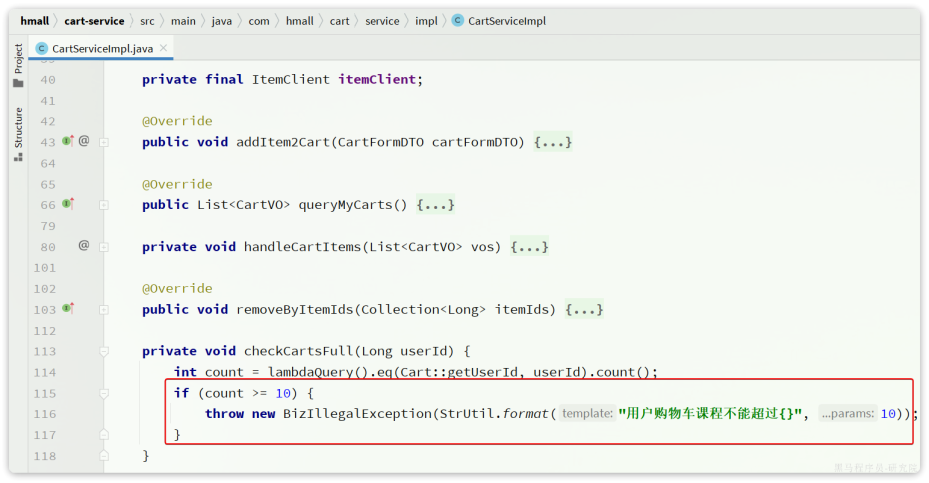

**业务方法整理示例**，位于原 CartServiceImpl 中：

```java
private final CartProperties cartProperties;

private void checkCartsFull(Long userId) {
    int maxItems = cartProperties.getMaxItems();
    if (maxItems < 1) {
        throw new IllegalStateException("购物车上限必须为正数");
    }
    long count = lambdaQuery().eq(Cart::getUserId, userId).count();
    if (count >= maxItems) {
        throw new IllegalStateException("购物车商品条目不能超过 " + maxItems);
    }
}
```

示例异常类型可按工程规范替换为业务异常。每次判断读取配置对象中的当前值，不要在构造函数中复制一份到永久常量。

| 概念 | 需要明确的规则 |
| --- | --- |
| 条目数 | 课件按购物车记录数 count 判断，不等于所有 num 相加 |
| 已存在商品增加数量 | 是否增加条目，要与添加逻辑一致 |
| 上限调低 | 已超限的旧数据如何展示、是否允许继续修改 |
| 并发添加 | 多个请求可能同时通过 count 检查 |

热更新解决参数维护，不保证并发下严格不超限。若业务要求强约束，需要结合用户维度的串行控制、锁或其他一致性方案。

**验证场景**：从 10 改成 20 后，不重启应用，再执行新增条目的校验；从 20 调回 10 时，也验证已有数据和新增行为。应确认修改的是应用实际读取的 namespace、group 与 Data ID。


## 23. 动态路由的数据格式

静态路由写在本地 YAML 中，修改后通常需要重启。课件将路由配置保存到 Nacos，并监听变化，实时更新网关。（课件第 64—67 页）

**动态路由链路**：

```text
Nacos gateway-routes.json
    → 首次读取 + 后续监听
    → JSON 转 RouteDefinition 列表
    → 更新路由定义仓库
    → 通知运行中的路由缓存刷新
    → 新请求按更新后的路由匹配
```

课件第 67 页给出单个 JSON 路由对象。若统一管理多条路由，可在外面包成数组；监听器和解析器必须约定同一种格式。

**整理示例：gateway-routes.json**：

```json
[
  {
    "id": "dyn-item",
    "uri": "lb://item-service",
    "predicates": [
      {
        "name": "Path",
        "args": {
          "_genkey_0": "/items/**",
          "_genkey_1": "/search/**"
        }
      }
    ],
    "filters": []
  }
]
```

等价的静态 YAML 片段是：

```yaml
spring:
  cloud:
    gateway:
      routes:
        - id: dyn-item
          uri: lb://item-service
          predicates:
            - Path=/items/**,/search/**
```

`_genkey_0`、`_genkey_1` 对应快捷配置参数的位置；`name` 使用工厂名 Path，不是 Java 类的完整名称。

Data ID `gateway-routes.json` 与 `dyn-` 前缀是整理示例约定，不是框架固定要求。若这条动态路由接管了本地 item 路由，应移除对应静态定义，避免两份规则同时匹配。


## 24. Nacos 首次读取与变更监听

只添加监听器，应用刚启动时可能没有路由；只调用一次 getConfig，又无法接收后续变化。课件用 `getConfigAndSignListener` 同时获取初始内容并注册监听器。（课件第 65 页）

关键类型：

| 类型 | 用途 |
| --- | --- |
| `com.alibaba.cloud.nacos.NacosConfigManager` | 获取配置客户端 |
| `com.alibaba.nacos.api.config.listener.Listener` | 接收配置变更 |
| `ConfigService` | Nacos 配置读写与监听 API |

**整理示例**：路由应用方法放在下一节的 DynamicRouteUpdater 中。用专用单线程执行回调，并让初始加载与回调在同一锁中处理，避免初始化期间旧内容晚于新内容应用。

```java
@Component
@RequiredArgsConstructor
public class DynamicRouteConfigListener {
    private static final Logger log =
        LoggerFactory.getLogger(DynamicRouteConfigListener.class);
    private static final String DATA_ID = "gateway-routes.json";
    private static final String GROUP = "DEFAULT_GROUP";

    private final NacosConfigManager nacosConfigManager;
    private final DynamicRouteUpdater routeUpdater;
    private final Object initLock = new Object();
    private final ExecutorService callbackExecutor =
        Executors.newSingleThreadExecutor();

    private final Listener listener = new Listener() {
        @Override
        public Executor getExecutor() {
            return callbackExecutor;
        }

        @Override
        public void receiveConfigInfo(String configInfo) {
            synchronized (initLock) {
                try {
                    routeUpdater.update(configInfo);
                } catch (RuntimeException e) {
                    log.error("动态路由更新失败，需要检查配置与当前路由状态", e);
                }
            }
        }
    };

    @PostConstruct
    public void init() throws NacosException {
        try {
            synchronized (initLock) {
                String initial = nacosConfigManager.getConfigService()
                    .getConfigAndSignListener(
                        DATA_ID, GROUP, 5000, listener);
                routeUpdater.update(initial);
            }
        } catch (NacosException | RuntimeException e) {
            close();
            throw e;
        }
    }

    @PreDestroy
    public void close() {
        nacosConfigManager.getConfigService()
            .removeListener(DATA_ID, GROUP, listener);
        callbackExecutor.shutdown();
    }
}
```

示例中的 `@PostConstruct`、`@PreDestroy` 对应 Java 11 / Boot 2 工程常见的 `javax.annotation` 体系，需有相应依赖。5000 为初次获取配置的超时毫秒数，不是路由刷新频率。

这里只注销自己添加的监听器并关闭自己的执行器，不应关闭由其他组件共享的整个 ConfigService。配置客户端仍需按第 20 节连接到正确的 Nacos 环境；网关应用名应使用它自己的名称。

此示例把初始配置缺失或无效视为启动失败，避免网关在没有预期路由时悄悄上线。其他启动策略需要明确设计。


## 25. RouteDefinitionWriter 与路由缓存刷新

收到 JSON 后还需要完成解析、保存、删除已移除的规则，并让运行中的路由视图更新。（课件第 66—67 页；缓存刷新为整理补充）

课件接口：

```java
Mono<Void> save(Mono<RouteDefinition> route);
Mono<Void> delete(Mono<String> routeId);
```

在课件常见的内存仓库中，save 可覆盖同 ID 定义；delete 按 ID 删除。`Mono` 必须被订阅执行，单纯调用方法并丢弃返回值，不能认为写入已经完成。

**整理示例：动态配置按完整列表替换**。只管理本监听器维护的 dyn- 路由；解析与基本校验通过后才开始修改。

```java
@Component
@RequiredArgsConstructor
public class DynamicRouteUpdater {
    private final ObjectMapper objectMapper;
    private final RouteDefinitionWriter writer;
    private final ApplicationEventPublisher publisher;
    private Set<String> managedIds = new HashSet<>();

    public synchronized void update(String json) {
        if (json == null || json.isBlank()) {
            throw new IllegalArgumentException("路由配置为空");
        }
        final List<RouteDefinition> routes;
        try {
            routes = objectMapper.readValue(
                json, new TypeReference<List<RouteDefinition>>() {});
        } catch (JsonProcessingException e) {
            throw new IllegalArgumentException("路由 JSON 无法解析", e);
        }
        if (routes == null) {
            throw new IllegalArgumentException("路由配置必须是数组");
        }

        Set<String> nextIds = new HashSet<>();
        for (RouteDefinition route : routes) {
            if (route == null || route.getId() == null
                    || !route.getId().startsWith("dyn-")
                    || route.getId().length() == 4
                    || !nextIds.add(route.getId())) {
                throw new IllegalArgumentException("动态路由 ID 非法或重复");
            }
            URI uri = route.getUri();
            String scheme = uri == null ? null : uri.getScheme();
            if (scheme == null || !Set.of("lb", "http", "https")
                    .contains(scheme.toLowerCase(Locale.ROOT))) {
                throw new IllegalArgumentException("路由目标协议不合法");
            }
            if (route.getPredicates() == null
                    || route.getPredicates().isEmpty()) {
                throw new IllegalArgumentException("必须明确路由匹配条件");
            }
        }

        Set<String> removedIds = new HashSet<>(managedIds);
        removedIds.removeAll(nextIds);

        Flux.fromIterable(routes)
            .concatMap(route -> writer.save(Mono.just(route)))
            .thenMany(Flux.fromIterable(removedIds)
                .concatMap(id -> writer.delete(Mono.just(id))))
            .then()
            .block(Duration.ofSeconds(10));

        managedIds = nextIds;
        publisher.publishEvent(new RefreshRoutesEvent(this));
    }
}
```

关键 import 包括 `com.fasterxml.jackson.core.type.TypeReference`、`org.springframework.cloud.gateway.route.RouteDefinitionWriter`、`org.springframework.cloud.gateway.event.RefreshRoutesEvent` 与 Reactor 的 Flux / Mono。

这里用 `block` 等待写入完成，调用位置限定为**启动线程或上一节的专用配置回调线程**，不能把该方法接到 Netty 请求事件循环。这样的写法用于说明顺序，其他实现可用串行响应式队列。

| 步骤 | 为什么需要 |
| --- | --- |
| 完整解析与基本校验 | 格式错误、重复 ID 等在写入前被拒绝 |
| 保存新定义 | 更新新增或变化的路由 |
| 删除旧集合中已消失的 ID | 防止配置删除后旧路由仍存在 |
| 刷新事件 | 通知运行中的路由缓存重建 |

显式 `[]` 在此示例中表示清空本监听器管理的动态路由；空白文本则被视为错误。两者语义不同，应由配置发布规范明确。


## 26. 动态路由的一致性与更新边界

监听成功、写入成功、运行视图刷新成功是不同阶段，不能仅看到 Nacos 发布提示就判定路由已生效。

| 风险点 | 判断与改进 |
| --- | --- |
| 配置格式正确，过滤器或断言却无效 | 还需验证工厂名称、参数、目标服务和权限 |
| 只保存新路由 | 已删除的规则可能继续生效，要计算旧新差集 |
| 多次变更并发处理 | 串行处理并记录配置版本，避免旧更新覆盖新更新 |
| 更新中途失败 | 多次 save / delete 通常不构成一个事务 |
| 静态与动态规则重叠 | 明确每个配置来源的所有权与路由顺序 |
| 多个网关实例 | 每个实例都要收到并成功应用变化 |

上一节是教学用实现：解析阶段失败时不会动仓库；**写入或缓存重建阶段失败时，不能承诺完整回滚**。保存几个路由后报错，仓库可能处于部分更新状态；需要告警、重新对账，并根据仓库实现设计重试或恢复。

若要求严格切换，可在独立仓库中先构建并验证完整的新版本，再切换版本视图，并保留上一版用于回退。不要把多个异步 `subscribe()` 当成原子更新。

`managedIds` 仅是进程内状态。若改用持久化或共享路由仓库，还需要在启动时恢复管理范围和版本，不能直接照搬这段集合管理方式。

动态路由还会改变可访问的服务与路径。Nacos 配置发布者应具有对应权限，目标 URI 要受约束；保留版本历史、灰度验证与回退手段，避免误把内部接口暴露到外部。


## 27. 联调顺序与故障排查

按路由、身份、配置三个层次验证，能更快定位问题。以下供读者在自己的工程中操作，本次笔记没有实际启动课程服务。

| 验证层 | 操作与预期 |
| --- | --- |
| 静态路由 | 经网关访问商品接口，与直接访问提供者比较路径和返回 |
| 注册发现 | 同服务多实例时观察目标日志，确认实际实例可达 |
| 身份校验 | 受保护请求分别使用缺失、过期、错误与有效 JWT |
| 身份头清理 | 外部伪造 user-info，确认不能变成该用户 |
| 用户上下文 | 连续用不同用户请求，确认无串用；检查异常后清理 |
| Feign 传递 | 交易服务调用下游后，下游读取到同一可信用户 |
| 配置共享 | 核对 JDBC 模板最终解析的数据库名与配置来源 |
| 业务热更新 | 修改购物车上限，不重启服务验证新的校验行为 |
| 动态路由 | 验证首次加载、修改目标、增加路由和删除路由 |
| 无效配置 | 错误 JSON、重复 ID、非法工厂参数等要有明确失败反馈 |

| 现象 | 优先排查 |
| --- | --- |
| 网关无法正常启动 | WebFlux / MVC 依赖冲突、端口占用、版本兼容 |
| 网关 404 | 路由未匹配，或匹配后提供者路径不对 |
| lb 路由 503 | LoadBalancer、服务名、实例发现与可达性 |
| 有效登录仍 401 | 令牌格式、验证配置、有效期、路径白名单 |
| 下游用户为空 | 是否传了修改后的 exchange，MVC 拦截器是否注册 |
| 第二跳用户为空 | Feign 拦截器未生效，或执行已切换到其他线程 |
| Nacos 配置读取不到 | config 依赖、bootstrap 机制、namespace / group / Data ID |
| 配置改了业务仍不变 | refresh 设置、属性对象注册、绑定方式、旧值缓存 |
| 动态路由删除后仍能访问 | 旧 ID 未删除、静态重复定义、其他实例未刷新 |
| 动态配置有变但请求没变 | 是否实际订阅 writer 操作，路由缓存是否刷新成功 |

跨域预检、业务权限拒绝与令牌无效是不同问题，应分别检查状态码、响应日志和实际请求。日志排查时避免打印完整 JWT 或配置密码。


## 28. 核心回顾与面试提示

本篇建立两条完整链路：

```text
请求链路：
路由匹配 → 网关验 JWT → 写内部身份头
→ 服务 MVC 拦截器 → ThreadLocal → 业务授权
→ Feign 拦截器 → 下游内部身份头

配置链路：
Nacos 配置 → 启动读取 / 变更通知
→ 属性绑定或 Bean 刷新
→ 业务按新值运行

路由配置还需：
解析 RouteDefinition → 保存 / 删除 → 路由缓存刷新
```

| 判断点 | 应掌握的结论 |
| --- | --- |
| 断言与过滤器 | 前者决定是否匹配，后者处理匹配后的请求与响应 |
| GlobalFilter 与 GatewayFilter | 自动参与匹配路由的公共链，与显式配置到路由的过滤器 |
| PRE 与 POST | 按嵌套链执行，需结合响应式完成、异常和取消理解 |
| 身份传递 | 请求头是传输载体，可信性需要入口校验与内部调用边界 |
| ThreadLocal | 只在当前线程可见，必须清理，不自动跨服务或异步线程 |
| Feign RequestInterceptor | 为新建的出站请求写入必要的可信身份 |
| 配置共享 | 公共模板与服务差异分开，配置入口和定位必须一致 |
| 热更新 | 配置变化还要通过绑定或刷新机制被业务使用 |
| 动态路由 | 初始读取、监听、解析、保存、删除与缓存刷新缺一不可 |

**面试提示**：用“用户下单后清理购物车”说明 JWT、网关、MVC 拦截器、ThreadLocal 和 Feign 拦截器如何协作；解释为什么仅信任 user-info 请求头不够、为什么 ThreadLocal 必须清理；再说明 bootstrap 的作用、普通 Value 为何不自动刷新，以及动态路由为什么不能只调用 save 而不处理删除和缓存刷新。
